# Decision Tree v3 — Giảm độ sâu cây

**Người thực hiện:** Lê Văn Hiếu — 3124411091.

## 1. Mục tiêu

Kiểm tra việc giảm độ sâu tối đa từ 5 xuống 3 ảnh hưởng thế nào
đến hiệu năng Validation và gap Train–Validation.

## 2. Thiết kế thí nghiệm

- Kế thừa Decision Tree v1.
- Chỉ đổi max_depth từ 5 thành 3.
- Giữ nguyên 36 đặc trưng và các tham số còn lại.
- Sử dụng cùng bộ chia và 5 fold của nhóm.
- Không đánh giá trên Test.

In [1]:
import json
from pathlib import Path

# Tìm thư mục final dù notebook được mở từ đâu trong repo
candidates = [Path.cwd(), Path.cwd() / "final", *Path.cwd().parents]
PROJECT_DIR = next(
    p for p in candidates
    if (p / "src" / "data.py").is_file()
)


RUN_DIR = (
    PROJECT_DIR / "experiments" / "runs"
    / "m02_decision_tree_v3_20261105T170001_06914c1a"
)

# Đọc kết quả đã lưu
metrics_v3 = json.loads(
    (RUN_DIR / "metrics.json").read_text(encoding="utf-8")
)

print("Run:", metrics_v3["run_id"])
print("Macro-F1 CV:", metrics_v3["cv"]["valid_f1_macro_mean"])

Run: m02_decision_tree_v3_20261105T170001_06914c1a
Macro-F1 CV: 0.6602836200700625


In [2]:
import pandas as pd

# Đọc kết quả v1 để làm mốc
RUN_V1 = (
    PROJECT_DIR / "experiments" / "runs"
    / "m02_decision_tree_v1_20261104T095332_6d8b7c85"
)

metrics_v1 = json.loads(
    (RUN_V1 / "metrics.json").read_text(encoding="utf-8")
)

# Lấy cùng các chỉ số từ hai lần chạy
comparison = pd.DataFrame({
    "Chỉ số": [
        "Macro-F1 Train",
        "Macro-F1 Validation",
        "Gap Train–Validation",
        "Recall Dropout",
        "Recall Enrolled",
    ],
    "v1 — độ sâu 5": [
        metrics_v1["cv"][key] for key in [
            "train_f1_macro_mean",
            "valid_f1_macro_mean",
            "gap_f1_macro_mean",
            "valid_recall_Dropout_mean",
            "valid_recall_Enrolled_mean",
        ]
    ],
    "v3 — độ sâu 3": [
        metrics_v3["cv"][key] for key in [
            "train_f1_macro_mean",
            "valid_f1_macro_mean",
            "gap_f1_macro_mean",
            "valid_recall_Dropout_mean",
            "valid_recall_Enrolled_mean",
        ]
    ],
})

display(comparison.round(4))

,Chỉ số,v1 — độ sâu 5,v3 — độ sâu 3
0,Macro-F1 Train,0.6877,0.6603
1,Macro-F1 Validation,0.6472,0.6603
2,Gap Train–Validation,0.0405,-0.0000
3,Recall Dropout,0.7010,0.6561
4,Recall Enrolled,0.2976,0.3780


V1 — cây sâu tối đa 5


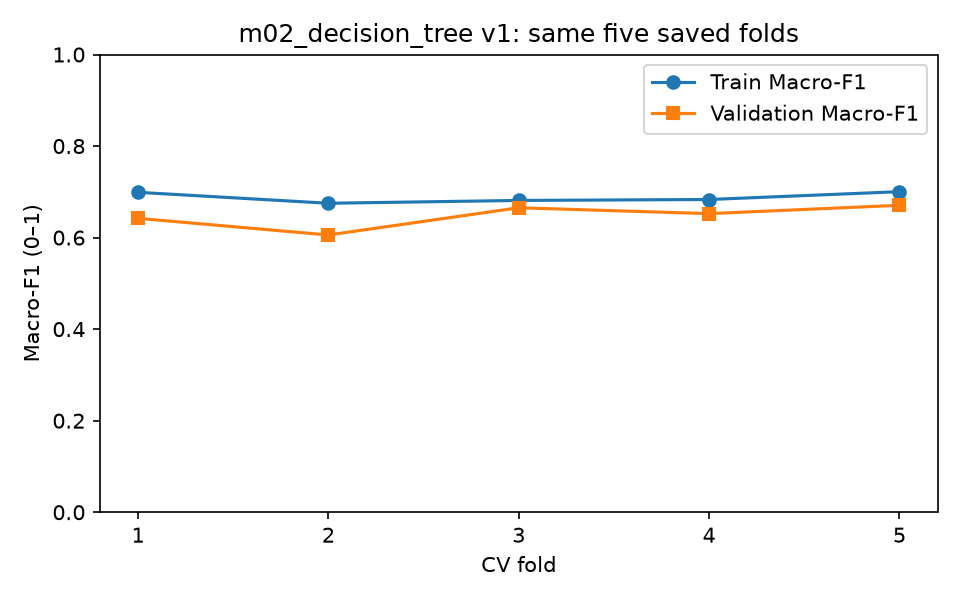

V3 — cây sâu tối đa 3


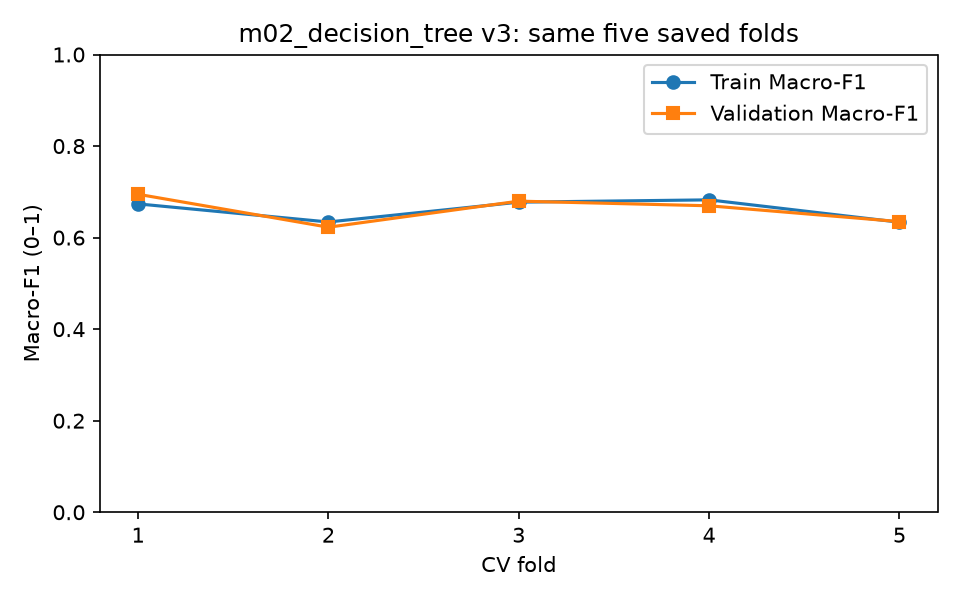

In [3]:
from IPython.display import Image, display

print("V1 — cây sâu tối đa 5")
display(Image(filename=str(
    RUN_V1 / "figures" / "cv_macro_f1.png"
)))

print("V3 — cây sâu tối đa 3")
display(Image(filename=str(
    RUN_DIR / "figures" / "cv_macro_f1.png"
)))

## 3. Nhận xét và kết luận

Khi giảm max_depth từ 5 xuống 3, giữ nguyên các yếu tố khác:

- Macro-F1 Validation trung bình tăng từ 0,6472 lên 0,6603.
- Macro-F1 Train giảm từ 0,6877 xuống 0,6603.
  Gap Train–Validation giảm từ 0,0405 xuống gần 0.
- Recall Enrolled tăng từ 29,76% lên 37,80%.
- Recall Dropout giảm từ 70,10% xuống 65,61%.

Kết quả trên cùng 5 fold cho thấy cây đơn giản hơn có chênh lệch
Train–Validation nhỏ hơn và Macro-F1 Validation trung bình cao hơn,
nhưng đánh đổi khả năng phát hiện sinh viên Dropout.

Vì vậy, chưa kết luận v3 tốt hơn toàn diện hoặc là mô hình tốt nhất
của nhóm. Thí nghiệm này chỉ kiểm tra tác động của việc giảm độ sâu
so với DT v1; chưa đánh giá trên Test.